In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from scipy.sparse import hstack  # Để concat sparse và dense nếu cần

In [2]:
!pip install gensim --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 88.6 MB/s eta 0:00:00


In [3]:
# load data from drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd

# Thay bằng link CSV thật của anh (phải là link công khai, trực tiếp đến file CSV)
url = '/content/drive/MyDrive/Bert/Data/clean_hochinhminh_khanhhoa_lamdong_binhdinh.csv' # Ví dụ: 'https://raw.githubusercontent.com/cs109/2014_data/master/countries.csv'

# Đọc file CSV từ URL
df = pd.read_csv(url)

# In ra 5 dòng đầu tiên
print(df.head(5))

   stt                hotel_name    country province_raw review_name  score  \
0    1    TTR Skypool View Hotel  Việt Nam       Đà Lạt        (k17   10.0   
1    2           Prime New Hotel  Việt Nam    Nha Trang         (mr    8.0   
2    3  The MCR Luxury Nha Trang  Việt Nam    Nha Trang        ,như   10.0   
3    4  Lavender Nha Trang Hotel  Việt Nam    Nha Trang        -dhn   10.0   
4    5      NAMI HOTEL Nha Trang  Việt Nam    Nha Trang        . pi    7.0   

   hotel_avg_score  deviation stay_duration  \
0              7.7        2.3         1 đêm   
1              7.8        0.2         3 đêm   
2              6.9        3.1         1 đêm   
3              8.9        1.1         1 đêm   
4              7.3       -0.3         6 đêm   

                                room_type  ...  \
0               Phòng Deluxe Giường Đôi  ...   
1    Suite Có Giường Cỡ King Nhìn Ra Biển  ...   
2    Phòng Deluxe Giường Đôi/2 Giường Đơn  ...   
3  Phòng Superior Giường Đôi Với Cửa Sổ 

In [5]:
df['review_info'] = df[['room_type_id', 'stay_duration_id', 'group_type_id']].values.tolist()
useful_columns = [
    'final',          # text chính để embed
    'hotel_info',
    'review_info',
    'score',
   # string list 7 số (sẽ convert sau)
    # thêm các cột khác bạn thấy quan trọng
]
df = df[useful_columns]
print(df.head(5))

                                               final  \
0  đánh giá: xuất_sắc ưu điểm: tốt về chất_lượng ...   
1  đánh giá: tiếc là đi vào ngày trời âm_u biển đ...   
2  đánh giá: xuất_sắc ưu điểm: phòng_ốc sạch_sẽ t...   
3  đánh giá: xuất_sắc ưu điểm: phòng sạch_sẽ gần ...   
4  đánh giá: hài_lòng ưu điểm: đối_diện biển rất ...   

                            hotel_info   review_info  score  
0  [8.4, 7.9, 7.9, 8.0, 8.0, 8.5, 8.2]   [408, 1, 3]   10.0  
1  [8.5, 7.7, 8.0, 8.0, 8.3, 8.9, 8.5]  [1205, 3, 0]    8.0  
2  [7.8, 6.6, 7.1, 5.5, 7.3, 6.7, 6.9]   [638, 1, 0]   10.0  
3  [9.2, 8.9, 9.1, 9.2, 9.3, 9.1, 9.2]   [985, 1, 0]   10.0  
4  [8.0, 7.6, 7.5, 7.7, 8.1, 8.7, 9.2]   [512, 6, 0]    7.0  


In [6]:
df.loc[:, 'label'] = df['score'].astype(int)
hotel_features = pd.json_normalize(df['hotel_info']).add_prefix('h_').fillna('')
review_features = pd.json_normalize(df['review_info']).add_prefix('r_').fillna('')

# Nếu chỉ dùng text → bỏ qua ghép, trực tiếp:
X_text = df['final']

# Nếu muốn ghép metadata vào text (thường cho kết quả tốt hơn):
df['final_enhanced'] = (
    df['hotel_info'].apply(lambda x: f"Hotel {x.get('name', 'Unknown')} - {x.get('stars', '')} stars | " if isinstance(x, dict) else "")
    + df['final']
)

X = df['final']

y = df['label']


In [7]:
from sklearn.model_selection import train_test_split

# Giả sử docs = df['final'] và labels = df['label']
docs = df['final']
labels = df['score'].astype(int)

# Bước 1: Tách tập Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    docs, labels, test_size=0.2, random_state=42
)

# Bước 2: Tách tập Validation từ tập Train hiện tại (15% của 80% còn lại)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42
)

# Kiểm tra quân số các tập
print(f"--- KẾT QUẢ CHIA DỮ LIỆU ---")
print(f"Tổng mẫu: {len(docs)}")
print(f"Tập Train (68%): {len(X_train)} mẫu")
print(f"Tập Validation (12%): {len(X_val)} mẫu")
print(f"Tập Test (20%): {len(X_test)} mẫu")

--- KẾT QUẢ CHIA DỮ LIỆU ---
Tổng mẫu: 41136
Tập Train (68%): 27971 mẫu
Tập Validation (12%): 4937 mẫu
Tập Test (20%): 8228 mẫu


In [8]:
import nltk

# Download cả hai để chắc chắn
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [9]:
# 1. Import các thư viện cần thiết
import numpy as np
import pandas as pd
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from gensim.utils import simple_preprocess
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [10]:
# ────────────────────────────────────────────────
# 2. Định nghĩa class Doc2VecVectorizer (để dùng trong Pipeline)
# ────────────────────────────────────────────────
class Doc2VecVectorizer(BaseEstimator, TransformerMixin):
    """
    Transformer để chuyển text → Doc2Vec vector
    Dùng infer_vector cho cả train và test
    """
    def __init__(self, model):
        self.model = model

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return np.array([
            self.model.infer_vector(
                simple_preprocess(text.lower())   # ← XÓA max_vocab_size ở đây
            )
            for text in X
        ])

In [11]:
# ────────────────────────────────────────────────
# 3. Chuẩn bị dữ liệu TaggedDocument để TRAIN Doc2Vec
# ────────────────────────────────────────────────
# Giả sử X_train là list[str] hoặc pd.Series
documents = [
    TaggedDocument(
        words=simple_preprocess(text.lower()),   # thay bằng word_tokenize nếu dùng underthesea
        tags=[i]
    )
    for i, text in enumerate(X_train)
]

In [12]:
# ────────────────────────────────────────────────
# 4. Huấn luyện Doc2Vec model
# ────────────────────────────────────────────────
print("Đang huấn luyện Doc2Vec...")

d2v_model = Doc2Vec(
    documents=documents,
    vector_size=200,          # 128–300 thường tốt, 200 là lựa chọn cân bằng
    window=5,                 # ngữ cảnh gần
    min_count=2,              # bỏ từ quá hiếm
    workers=4,                # số luồng (tùy CPU)
    dm=1,                     # 1 = PV-DM (thường tốt hơn cho phân loại), 0 = PV-DBOW
    epochs=30,                # 20–60 tùy lượng dữ liệu (ít dữ liệu thì tăng epochs)
    seed=42,
    negative=5,               # negative sampling
    hs=0                      # 0 = negative sampling, 1 = hierarchical softmax
)

print("Doc2Vec đã huấn luyện xong. Số từ trong vocab:", len(d2v_model.wv))

Đang huấn luyện Doc2Vec...
Doc2Vec đã huấn luyện xong. Số từ trong vocab: 6233


In [13]:
# ────────────────────────────────────────────────
# 5. Tạo Pipeline hoàn chỉnh - CHUYỂN SANG RANDOM FOREST
# ────────────────────────────────────────────────

from sklearn.ensemble import RandomForestClassifier

pipeline = Pipeline([
    ('doc2vec',  Doc2VecVectorizer(d2v_model)),
    # KHÔNG CẦN StandardScaler nữa vì RandomForest không nhạy cảm với scale
    # ('scaler',   StandardScaler()),   # ← comment hoặc xóa dòng này

    ('clf',      RandomForestClassifier(
        n_estimators=300,               # số cây, 100-500 là phổ biến
        criterion='gini',               # hoặc 'entropy'/'log_loss'
        max_depth=None,                 # None = không giới hạn (thường tốt)
        min_samples_split=2,
        min_samples_leaf=1,
        max_features='sqrt',            # 'sqrt' hoặc 'log2' giúp tránh overfit
        bootstrap=True,                 # True = bagging (mặc định)
        class_weight='balanced_subsample',  # rất tốt khi nhãn mất cân bằng
        random_state=42,
        n_jobs=-1,                      # dùng hết core CPU để train nhanh
        verbose=1                       # in tiến trình nếu muốn theo dõi
    ))
])

In [14]:
# ────────────────────────────────────────────────
# 6. Huấn luyện toàn bộ pipeline
# ────────────────────────────────────────────────
print("Đang fit pipeline...")
pipeline.fit(X_train, y_train)
print("Pipeline đã fit xong!")

Đang fit pipeline...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    3.2s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:   16.5s


Pipeline đã fit xong!


[Parallel(n_jobs=-1)]: Done 300 out of 300 | elapsed:   27.6s finished


In [15]:
# ────────────────────────────────────────────────
# ĐÁNH GIÁ MÔ HÌNH - Doc2Vec + Classifier (SVC/RF)
# ────────────────────────────────────────────────

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
import numpy as np

# Dự đoán (nếu chưa có)
y_pred = pipeline.predict(X_test)

# Chuyển về numpy array (thường không cần vì sklearn đã trả np.array)
y_true = np.asarray(y_test)
y_pred = np.asarray(y_pred)

# ----------------------------------------------------------------------
# Tính metric cơ bản
# ----------------------------------------------------------------------
accuracy = accuracy_score(y_true, y_pred)

# In đẹp
print("\n" + "="*80)
print("          MODEL EVALUATION ON TEST SET")
print("     " + ("Doc2Vec + LinearSVC" if 'LinearSVC' in str(pipeline.named_steps['clf'])
               else "Doc2Vec + RandomForest"))
print("="*80)

print(f"\nOverall Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print("-"*60)

# ----------------------------------------------------------------------
# Classification Report
# ----------------------------------------------------------------------
try:
    class_names = [str(c) for c in pipeline.named_steps['clf'].classes_]
except:
    class_names = None

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    digits=4,
    zero_division=0,
    target_names=class_names
))

# ----------------------------------------------------------------------
# Confusion Matrix
# ----------------------------------------------------------------------
cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix (Raw counts):")
print(cm)

cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_normalized = np.nan_to_num(cm_normalized)

print("\nConfusion Matrix (Row-normalized - %):")
print(np.round(cm_normalized * 100, 2))

# ----------------------------------------------------------------------
# Summary Metrics
# ----------------------------------------------------------------------
print("\nSummary Metrics:")
print(f"  Macro Avg Precision : {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"  Macro Avg Recall    : {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"  Macro Avg F1        : {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"  Weighted Avg F1     : {f1_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")

print("\n" + "="*80)
print(f"HOÀN TẤT ĐÁNH GIÁ!  •  Test Accuracy = {accuracy*100:.2f}%")
print("="*80 + "\n")


          MODEL EVALUATION ON TEST SET
     Doc2Vec + RandomForest

Overall Accuracy: 0.5865 (58.65%)
------------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

           5     0.0000    0.0000    0.0000       194
           6     0.3750    0.0142    0.0273       212
           7     0.0000    0.0000    0.0000       483
           8     0.6966    0.0560    0.1037      1107
           9     0.9888    0.1554    0.2686      1712
          10     0.5718    0.9945    0.7261      4520

    accuracy                         0.5865      8228
   macro avg     0.4387    0.2033    0.1876      8228
weighted avg     0.6233    0.5865    0.4694      8228


Confusion Matrix (Raw counts):
[[   0    0    0    0    0  194]
 [   0    3    0    0    0  209]
 [   0    0    0    6    1  476]
 [   0    0    0   62    0 1045]
 [   0    0    1    3  266 1442]
 [   0    5    0   18    2 4495]]

Confusion Matrix (Row-normalized - %)

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 300 out of 300 | elapsed:    0.1s finished


In [16]:
# ────────────────────────────────────────────────
# LƯU MODEL: Doc2Vec + LinearSVC Pipeline (cách ổn định nhất)
# ────────────────────────────────────────────────

import os
import joblib
from gensim.models.doc2vec import Doc2Vec

# Đường dẫn lưu (tạo thư mục nếu chưa có)
save_dir = '/content/drive/MyDrive/Bert/Model/Doc2vec-RF'
os.makedirs(save_dir, exist_ok=True)

doc2vec_path   = os.path.join(save_dir, 'doc2vec_model.d2v')
pipeline_path  = os.path.join(save_dir, 'pipeline_doc2vec_rf.joblib')

print("Đang lưu mô hình...")

try:
    # 1. Lưu riêng Doc2Vec model (gensim khuyến nghị dùng .save() thay vì pickle)
    d2v_model.save(doc2vec_path)
    print(f"✅ Đã lưu Doc2Vec model tại: {doc2vec_path}")
    print(f"   Kích thước: {os.path.getsize(doc2vec_path) / (1024 * 1024):.2f} MB")

    # 2. Lưu toàn bộ pipeline bằng joblib (tốt hơn pickle cho sklearn + gensim)
    joblib.dump(pipeline, pipeline_path, compress=('gzip', 3))  # nén nhẹ để tiết kiệm dung lượng
    print(f"✅ Đã lưu Pipeline (Doc2VecVectorizer + Scaler + LinearSVC) tại: {pipeline_path}")
    print(f"   Kích thước: {os.path.getsize(pipeline_path) / (1024 * 1024):.2f} MB")

    # Kiểm tra file tồn tại và > 0 bytes
    if os.path.exists(doc2vec_path) and os.path.getsize(doc2vec_path) > 0 and \
       os.path.exists(pipeline_path) and os.path.getsize(pipeline_path) > 0:
        print("\n" + "═"*60)
        print("🎉 LƯU THÀNH CÔNG TOÀN BỘ!")
        print("═"*60)
    else:
        print("⚠️ Một hoặc cả hai file không hợp lệ sau khi lưu.")

except Exception as e:
    print("❌ LỖI KHI LƯU:")
    print(f"→ {type(e).__name__}: {str(e)}")
    print("\nGợi ý khắc phục:")
    print("1. Đảm bảo pipeline đã fit thành công (pipeline.fit(X_train, y_train))")
    print("2. Nếu lỗi liên quan đến gensim → thử dùng joblib thay pickle như trên")
    print("3. Nếu vẫn lỗi → thử lưu riêng Doc2Vec trước rồi rebuild pipeline khi load")



Đang lưu mô hình...
✅ Đã lưu Doc2Vec model tại: /content/drive/MyDrive/Bert/Model/Doc2vec-RF/doc2vec_model.d2v
   Kích thước: 31.12 MB
✅ Đã lưu Pipeline (Doc2VecVectorizer + Scaler + LinearSVC) tại: /content/drive/MyDrive/Bert/Model/Doc2vec-RF/pipeline_doc2vec_rf.joblib
   Kích thước: 122.70 MB

════════════════════════════════════════════════════════════
🎉 LƯU THÀNH CÔNG TOÀN BỘ!
════════════════════════════════════════════════════════════


In [17]:
# ────────────────────────────────────────────────
# CÁCH LOAD LẠI ĐỂ KIỂM TRA (copy phần này để test sau)
# ────────────────────────────────────────────────
# Load lại
d2v_loaded = Doc2Vec.load(doc2vec_path)
pipeline_loaded = joblib.load(pipeline_path)

# Gán lại Doc2Vec vào vectorizer (vì khi lưu pipeline, object Doc2VecVectorizer giữ reference)
pipeline_loaded.named_steps['doc2vec'].model = d2v_loaded

# Test predict
sample_text = ["khách sạn rất tốt, sạch sẽ, nhân viên thân thiện"]
pred = pipeline_loaded.predict(sample_text)
print("Dự đoán mẫu:", pred)

Dự đoán mẫu: [10]


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 300 out of 300 | elapsed:    0.0s finished


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.1s
[Parallel(n_jobs=12)]: Done 300 out of 300 | elapsed:    0.1s finished


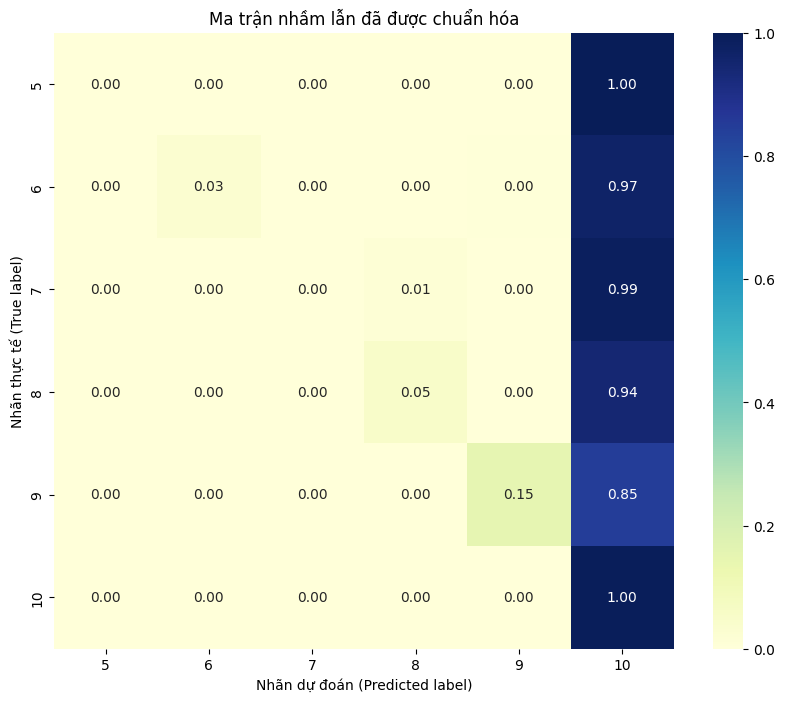

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns   # chỉ cần nếu bạn muốn dùng seaborn ở phần sau


y_pred = pipeline_loaded.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=pipeline_loaded.classes_)

cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Lấy tên các lớp dựa trên điểm rating thực tế
class_names = [str(i) for i in range(5, 11)]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='YlGnBu',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Ma trận nhầm lẫn đã được chuẩn hóa')
plt.ylabel('Nhãn thực tế (True label)')
plt.xlabel('Nhãn dự đoán (Predicted label)')
plt.show()


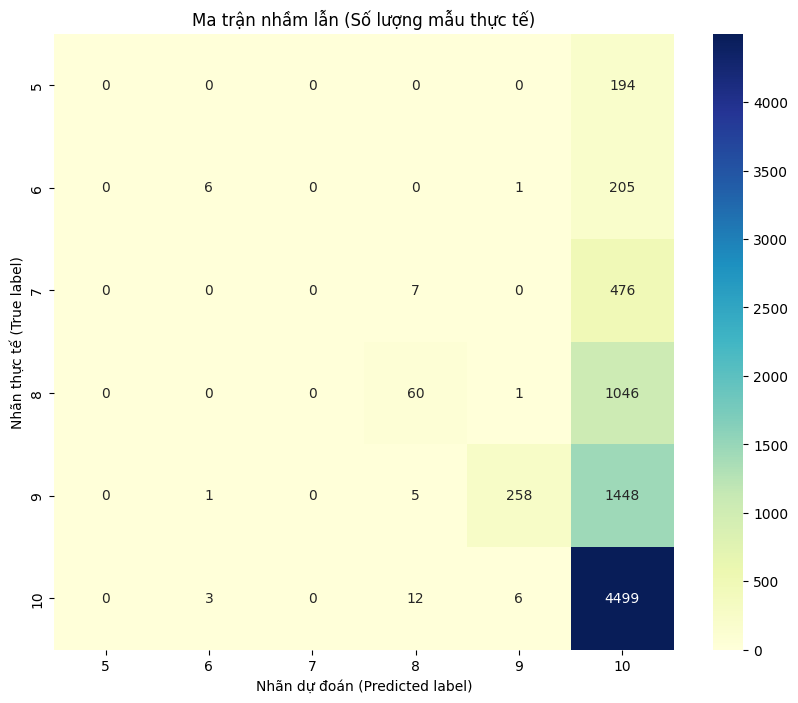

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Tính ma trận nhầm lẫn (đây là dạng số lượng gốc)
cm = confusion_matrix(y_test, y_pred, labels=pipeline_loaded.classes_)
# 2. Tên các lớp (từ 5 đến 10)
class_names = [str(i) for i in range(5, 11)]

plt.figure(figsize=(10, 8))

# 3. Vẽ Heatmap với biến 'cm' gốc
sns.heatmap(
    cm,
    annot=True,      # Hiển thị số lên ô
    fmt='d',         # ĐỊNH DẠNG LÀ SỐ NGUYÊN (d = decimal/integer)
    cmap='YlGnBu',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Ma trận nhầm lẫn (Số lượng mẫu thực tế)')
plt.ylabel('Nhãn thực tế (True label)')
plt.xlabel('Nhãn dự đoán (Predicted label)')
plt.show()